<a href="https://colab.research.google.com/github/RAHUL09072007/SOCIAL-MEDIA-DATA-ANALYSIS-SYSTEM/blob/main/REVIEW_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Social_Media_Data_Analysis_dataset.csv to Social_Media_Data_Analysis_dataset.csv

Dataset loaded successfully!
**************DATASET INSPECTION*******************

First 5 rows:
    Platform Post_Type  Hashtag_Count     Views Sentiment    Likes  Comments  \
0  Instagram     Image            8.0  257557.0  Negative  12104.0     895.0   
1  Instagram     Video            7.0  161140.0  Positive   5119.0     316.0   
2  Instagram     Image            4.0   20735.0   Neutral    493.0      40.0   
3   Facebook     Image            6.0   78616.0   Neutral   3215.0     246.0   
4    YouTube     Video            4.0  338261.0  Negative  14764.0     954.0   

   Shares  Engagement_Rate Engagement_Level  
0   301.0            6.027             High  
1   104.0            5.110              Low  
2     8.0            3.574              Low  
3   147.0            5.241              Low  
4   419.0            6.756             High  

Dataset shape:
(1200, 10)

Column names:
['Platform', 'Po

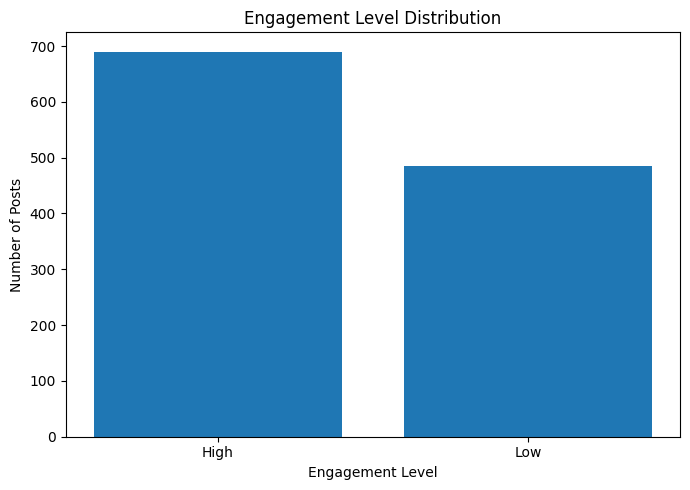

**************POST TYPE ANALYSIS*********************

High Engagement Rate by Post Type:
Video    73.333333
Image    41.834862
dtype: float64


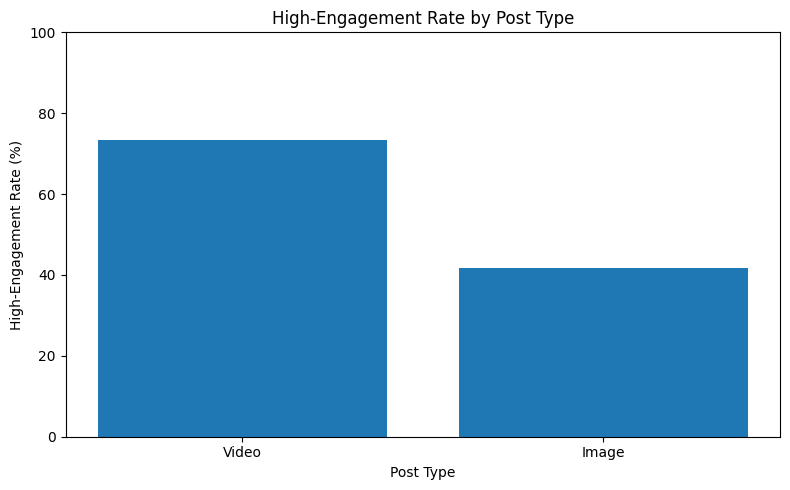

**********PLATFORM ANALYSIS*********************

High Engagement Rate by Platform:
YouTube      77.681159
Instagram    56.992084
Facebook     50.826446
Twitter      39.712919
dtype: float64


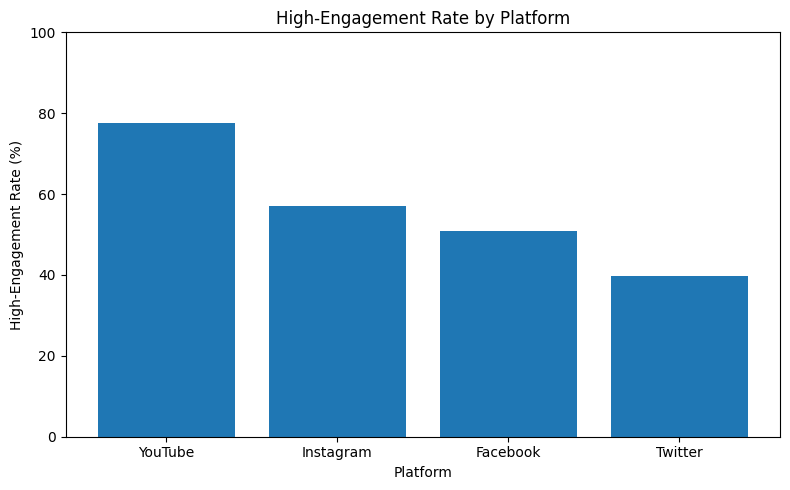

***************VIEWS ANALYSIS***********************

Average Views - High Engagement: 264378.1
Average Views - Low Engagement: 241053.52

Median Views - High Engagement: 272942.0
Median Views - Low Engagement: 231572.0


/tmp/ipykernel_2781/3729841340.py:177: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([high_views, low_views],labels=["High", "Low"])


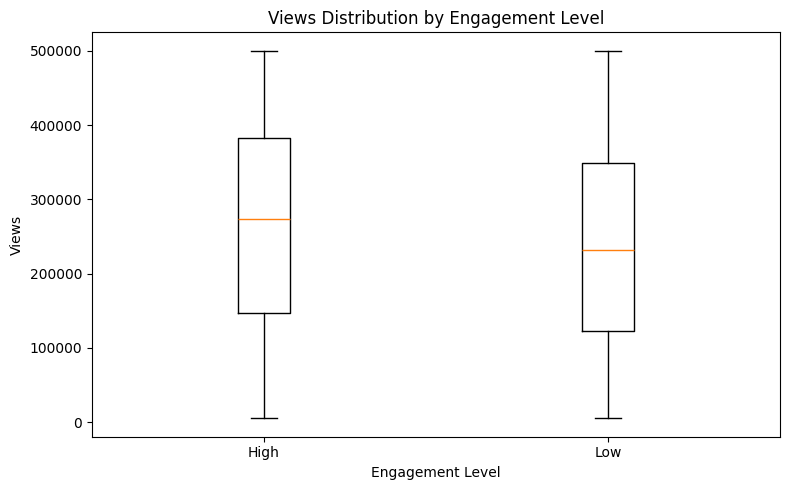

*********NUMERICAL STATISTICS************

VIEWS
Mean: 254750.51
Median: 254737.0
Standard Deviation: 139933.51
Minimum: 5320.0
Maximum: 499955.0

LIKES
Mean: 11937.24
Median: 10838.0
Standard Deviation: 8211.48

COMMENTS
Mean: 861.57
Median: 709.0
Standard Deviation: 666.66

SHARES
Mean: 511.23
Median: 403.0
Standard Deviation: 429.47
*************LOGISTIC REGRESSION*****************
High = 1
Low  = 0

Target distribution:
High: 690
Low : 485

Features used:
['Hashtag_Count', 'Views', 'Likes', 'Comments', 'Shares', 'Engagement_Rate']

Feature matrix shape:
(1175, 6)

Feature standardization completed.

Training samples: 940
Testing samples: 235
Training percentage: 80%
Testing percentage: 20%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()
df = pd.read_csv("Social_Media_Data_Analysis_dataset.csv")
print("\nDataset loaded successfully!")

print("**************DATASET INSPECTION*******************")

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("**********************MISSING VALUE CHECK*******************")

print("\nMissing values in each column:")
print(df.isnull().sum())
total_missing = df.isnull().sum().sum()
print("\nTotal missing values:", total_missing)

print("***************DUPLICATE CHECK**************************")

duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)


df = df.drop_duplicates()
print("\nAfter removing duplicates:")
print("df.shape")
print("Duplicate rows remaining:",df.duplicated().sum())

print("****************MISSING VALUE HANDLING***********************")

categorical_columns = [
    "Platform",
    "Post_Type",
    "Sentiment",
    "Engagement_Level"
]

numerical_columns = [
    "Hashtag_Count",
    "Views",
    "Likes",
    "Comments",
    "Shares",
    "Engagement_Rate"
]

# Fill categorical missing values using mode

for column in categorical_columns:

    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

# Fill numerical missing values using median

for column in numerical_columns:

    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].median()
        )

print("Categorical missing values filled using MODE.")
print("Numerical missing values filled using MEDIAN.")


print("************FINAL DATA CLEANING CHECK******************")

remaining_missing = df.isnull().sum().sum()
remaining_duplicates = df.duplicated().sum()
print("Missing values after cleaning:", remaining_missing)
print("Duplicate rows after cleaning:",remaining_duplicates)
print("Final dataset shape:",df.shape)

print("*************ENGAGEMENT LEVEL DISTRIBUTION*********************")

high_count = (df["Engagement_Level"] == "High").sum()
low_count = (df["Engagement_Level"] == "Low").sum()
total_records = len(df)
high_percentage = (high_count / total_records) * 100
low_percentage = (low_count / total_records) * 100

print("High Engagement:", high_count)
print("Low Engagement :", low_count)

print("\nHigh Engagement Rate:",round(high_percentage, 2),"%")
print("Low Engagement Rate:",round(low_percentage, 2),"%")

#ENGAGEMENT LEVEL GRAPH REPRESENTATION

plt.figure(figsize=(7, 5))
labels = ["High", "Low"]
values = [high_count, low_count]
plt.bar(labels, values)
plt.title("Engagement Level Distribution")
plt.xlabel("Engagement Level")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()

print("**************POST TYPE ANALYSIS*********************")

post_types = df["Post_Type"].unique()
post_type_rates = {}
for post_type in post_types:
    subset = df[df["Post_Type"] == post_type]
    high = (subset["Engagement_Level"] == "High").sum()
    total = len(subset)
    rate = (high / total) * 100
    post_type_rates[post_type] = rate
post_type_rates = pd.Series(post_type_rates).sort_values(ascending=False)
print("\nHigh Engagement Rate by Post Type:")
print(post_type_rates)

#POST TYPE GRAPH REPRESENTATION

plt.figure(figsize=(8, 5))
plt.bar(post_type_rates.index,post_type_rates.values)
plt.title("High-Engagement Rate by Post Type")
plt.xlabel("Post Type")
plt.ylabel("High-Engagement Rate (%)")
plt.ylim(0,100)
plt.tight_layout()
plt.show()


print("**********PLATFORM ANALYSIS*********************")
platforms = df["Platform"].unique()
platform_rates = {}
for platform in platforms:
    subset = df[df["Platform"] == platform]
    high = (subset["Engagement_Level"] == "High").sum()
    total = len(subset)
    rate = (high / total) * 100
    platform_rates[platform] = rate
    platform_rates = pd.Series(platform_rates).sort_values(ascending=False)
print("\nHigh Engagement Rate by Platform:")
print(platform_rates)

#PLATFORM GRAPH

plt.figure(figsize=(8, 5))
plt.bar(platform_rates.index,platform_rates.values)
plt.title("High-Engagement Rate by Platform")
plt.xlabel("Platform")
plt.ylabel("High-Engagement Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("***************VIEWS ANALYSIS***********************")
high_views = df[df["Engagement_Level"] == "High"]["Views"]
low_views = df[df["Engagement_Level"] == "Low"]["Views"]
print("\nAverage Views - High Engagement:",round(np.mean(high_views), 2))
print("Average Views - Low Engagement:",round(np.mean(low_views), 2))
print("\nMedian Views - High Engagement:", round(np.median(high_views), 2))
print("Median Views - Low Engagement:",round(np.median(low_views), 2))

#VIEW GRAPH

plt.figure(figsize=(8, 5))
plt.boxplot([high_views, low_views],labels=["High", "Low"])
plt.title("Views Distribution by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Views")
plt.tight_layout()
plt.show()

print("*********NUMERICAL STATISTICS************")

views = df["Views"].to_numpy()
likes = df["Likes"].to_numpy()
comments = df["Comments"].to_numpy()
shares = df["Shares"].to_numpy()

print("\nVIEWS")
print("Mean:",round(np.mean(views), 2))
print("Median:",round(np.median(views), 2))
print("Standard Deviation:",round(np.std(views), 2))
print("Minimum:",np.min(views))
print("Maximum:",np.max(views))

print("\nLIKES")
print("Mean:",round(np.mean(likes), 2))
print("Median:",round(np.median(likes), 2))
print("Standard Deviation:",round(np.std(likes), 2))

print("\nCOMMENTS")
print("Mean:",round(np.mean(comments), 2))
print("Median:",round(np.median(comments), 2))
print("Standard Deviation:",round(np.std(comments), 2))

print("\nSHARES")
print("Mean:",round(np.mean(shares), 2))
print("Median:",round(np.median(shares), 2))
print("Standard Deviation:",round(np.std(shares), 2))

print("*************LOGISTIC REGRESSION*****************")
y = np.where(df["Engagement_Level"] == "High",1,0)

print("High = 1")
print("Low  = 0")

print("\nTarget distribution:")
print("High:", np.sum(y == 1))
print("Low :", np.sum(y == 0))

features = [
    "Hashtag_Count",
    "Views",
    "Likes",
    "Comments",
    "Shares",
    "Engagement_Rate"
]

X = df[
    features
].to_numpy(dtype=float)

print("\nFeatures used:")
print(features)

print("\nFeature matrix shape:")
print(X.shape)


feature_mean = np.mean(
    X,
    axis=0
)

feature_std = np.std(
    X,
    axis=0
)

# Avoid division by zero
feature_std[
    feature_std == 0
] = 1

X_scaled = (
    X - feature_mean
) / feature_std

print("\nFeature standardization completed.")

np.random.seed(42)

indices = np.arange(
    len(X_scaled)
)

np.random.shuffle(indices)

split_index = int(
    0.80 * len(indices)
)

train_indices = indices[
    :split_index
]

test_indices = indices[
    split_index:
]

X_train = X_scaled[
    train_indices
]

X_test = X_scaled[
    test_indices
]

y_train = y[
    train_indices
]

y_test = y[
    test_indices
]

print("\nTraining samples:",
      len(X_train))

print("Testing samples:",
      len(X_test))

print("Training percentage: 80%")
print("Testing percentage: 20%")



